# U01.LAB03 · Ensambles, Reducción Dimensional y Green AI (Ejercicio 02)

- **Dataset:** Statlog (German Credit Data) - Repositorio UCI
- **Unidad de análisis:** Solicitudes y expedientes crediticios individuales
- **Target:** `class` (1: Buen riesgo, 2: Riesgo de impago / Clase prioritaria)
- **Métrica principal de decisión:** F1-macro (complementada con el Recall de la Clase 2)
- **Criterio de evaluación:** Frontera de Pareto entre desempeño predictivo y costo computacional (tiempo de ajuste)

In [12]:
import sys
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Acceso relativo al módulo src
src_path = str(Path("../src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, recall_score, classification_report

# Cargar dataset
df = pd.read_csv("../data/raw/dataset.csv")

TARGET = "class"
DROP_COLUMNS = ["foreign_worker", "own_telephone"]  # Mantenemos las exclusiones justificadas

X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# Preprocesamiento integrado
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# Partición congelada (80/20 estratificada con random_state=42)
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones de entrenamiento: {Xtr.shape}, Prueba: {Xte.shape}")

Dimensiones de entrenamiento: (800, 18), Prueba: (200, 18)


In [13]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA

# Paso 2: Crear el catálogo
# Utilizamos las configuraciones dadas e incorporamos la variante PCA
models = {
    "logistic": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000, random_state=42))]),
    "svm_c1": Pipeline([("prep", preprocess), ("model", SVC(C=1, probability=True, random_state=42))]),
    "svm_c10": Pipeline([("prep", preprocess), ("model", SVC(C=10, probability=True, random_state=42))]),
    "svm_pca": Pipeline([("prep", preprocess), ("pca", PCA(n_components=0.95, random_state=42)), ("model", SVC(C=10, probability=True, random_state=42))]),
    "rf_100": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1))]),
    "rf_300": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1))]),
    "boost": Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(max_depth=6, random_state=42))])
}

print(f"Catálogo creado con {len(models)} modelos listos para evaluación.")

Catálogo creado con 7 modelos listos para evaluación.


In [14]:
from time import perf_counter
from pathlib import Path
import joblib, numpy as np, pandas as pd
from sklearn.metrics import f1_score, recall_score

Path("reports/models").mkdir(parents=True,exist_ok=True)
rows=[]
for name,model in models.items():
    fit_times=[]
    for repetition in range(3):
        start=perf_counter(); model.fit(Xtr,ytr)
        fit_times.append(perf_counter()-start)
    start=perf_counter(); pred=model.predict(Xte)
    predict_ms=(perf_counter()-start)*1000
    path=Path("reports/models")/f"{name}.joblib"
    joblib.dump(model,path)
    rows.append({"model":name,"f1_macro":f1_score(yte,pred,average="macro"),
      "recall_macro":recall_score(yte,pred,average="macro"),
      "fit_median_s":np.median(fit_times),"predict_ms":predict_ms,
      "size_kb":path.stat().st_size/1024})
results=pd.DataFrame(rows)
display(results.sort_values("f1_macro",ascending=False))

c:\Users\Ricky\Universidad Autonoma de Santo Domingo\CI-MACDIA - Documents\Maestria IA y Ciencias de DAtos\3er. Modulo\INF8239_U01\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Ricky\Universidad Autonoma de Santo Domingo\CI-MACDIA - Documents\Maestria IA y Ciencias de DAtos\3er. Modulo\INF8239_U01\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Ricky\Universidad Autonoma de Santo Domingo\CI-MACDIA - Documents\Maestria IA y Ciencias de DAtos\3er. Modulo\INF8239_U01\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWar

,model,f1_macro,recall_macro,fit_median_s,predict_ms,size_kb
1,svm_c1,0.741713,0.722619,0.211668,26.4299,254.693359
2,svm_c10,0.738182,0.744048,0.280014,19.8839,259.787109
3,svm_pca,0.719495,0.723810,0.246596,19.0716,162.943359
0,logistic,0.706973,0.698810,0.078570,14.8592,7.494141
6,boost,0.661893,0.653571,0.336206,17.1956,211.876953
5,rf_300,0.641577,0.630952,0.678427,109.0611,3734.088867
4,rf_100,0.628735,0.620238,0.272326,41.8031,1253.135742


In [15]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Siguiendo la regla del manual: aplicamos PCA *solamente* al bloque numérico
num_pipe_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=42)) # Retenemos el 95% de la varianza numérica
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess_pca = ColumnTransformer([
    ("num", num_pipe_pca, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# Construimos el modelo combinando el preprocesamiento con PCA y la SVM (C=1 como en la guía)
svm_pca_step4 = Pipeline([
    ("prep", preprocess_pca),
    ("model", SVC(C=1, probability=True, random_state=42))
])

# Ajustamos con los datos de entrenamiento
svm_pca_step4.fit(Xtr, ytr)

# Extraemos el número de componentes desde adentro del ColumnTransformer
pca_obj = svm_pca_step4.named_steps["prep"].named_transformers_["num"].named_steps["pca"]
print("Componentes numéricos retenidos (PCA 95%):", pca_obj.n_components_)
print("Componentes numéricos originales:", len(num_cols))

c:\Users\Ricky\Universidad Autonoma de Santo Domingo\CI-MACDIA - Documents\Maestria IA y Ciencias de DAtos\3er. Modulo\INF8239_U01\INF8239_U01\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Componentes numéricos retenidos (PCA 95%): 6
Componentes numéricos originales: 7


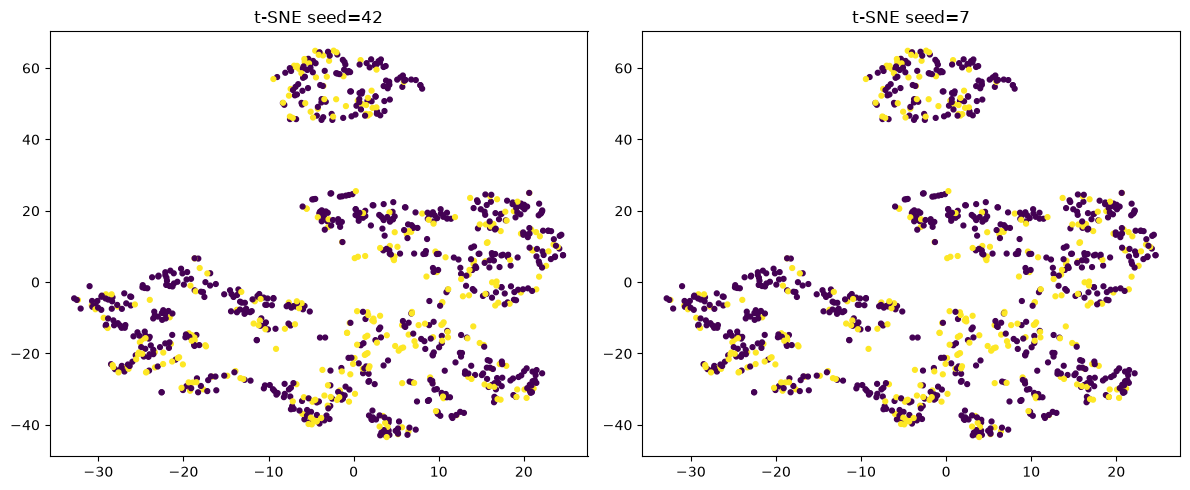

In [16]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd

# 1. Filtramos solo las numéricas y manejamos nulos (obligatorio para t-SNE)
X_num = X.select_dtypes(include="number").fillna(X.select_dtypes(include="number").median())

# 2. Tomamos la muestra (máximo 1000 filas para controlar el tiempo computacional)
sample = X_num.sample(min(1000, len(X_num)), random_state=42)
y_sample = y.loc[sample.index]

# 3. Escalamos los datos
scaled = StandardScaler().fit_transform(sample)

# 4. Configuramos el lienzo para 2 gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 5. Generamos dos proyecciones con semillas distintas (42 y 7)
for ax, seed in zip(axes, [42, 7]):
    emb = TSNE(
        n_components=2, 
        perplexity=30, 
        random_state=seed, 
        init="pca", 
        learning_rate="auto"
    ).fit_transform(scaled)
    
    ax.scatter(emb[:, 0], emb[:, 1], c=pd.Categorical(y_sample).codes, s=12, cmap="viridis")
    ax.set_title(f"t-SNE seed={seed}")

# 6. Ajustamos y guardamos la figura en la carpeta reports
plt.tight_layout()
plt.savefig("reports/tsne_two_seeds.png", dpi=160)
plt.show()

In [17]:
# Función  para determinar modelos dominados y no dominados
def pareto_flags(df, score="f1_macro", cost="fit_median_s"):
    flags = []
    for _, row in df.iterrows():
        # Un modelo está dominado si existe otro con mayor o igual F1 Y menor o igual tiempo
        # con al menos una desigualdad estricta
        dominated = ((df[score] >= row[score]) & (df[cost] <= row[cost]) & 
                     ((df[score] > row[score]) | (df[cost] < row[cost]))).any()
        flags.append(not bool(dominated))
    return flags


results["is_pareto"] = pareto_flags(results)

# Guardar la tabla final para el reporte
results.to_csv("reports/green_ai_results.csv", index=False)

# Mostrar la tabla ordenada priorizando los modelos Pareto óptimos
display(results.sort_values(["is_pareto", "f1_macro"], ascending=[False, False]))

,model,f1_macro,recall_macro,fit_median_s,predict_ms,size_kb,is_pareto
1,svm_c1,0.741713,0.722619,0.211668,26.4299,254.693359,True
0,logistic,0.706973,0.698810,0.078570,14.8592,7.494141,True
2,svm_c10,0.738182,0.744048,0.280014,19.8839,259.787109,False
3,svm_pca,0.719495,0.723810,0.246596,19.0716,162.943359,False
6,boost,0.661893,0.653571,0.336206,17.1956,211.876953,False
5,rf_300,0.641577,0.630952,0.678427,109.0611,3734.088867,False
4,rf_100,0.628735,0.620238,0.272326,41.8031,1253.135742,False


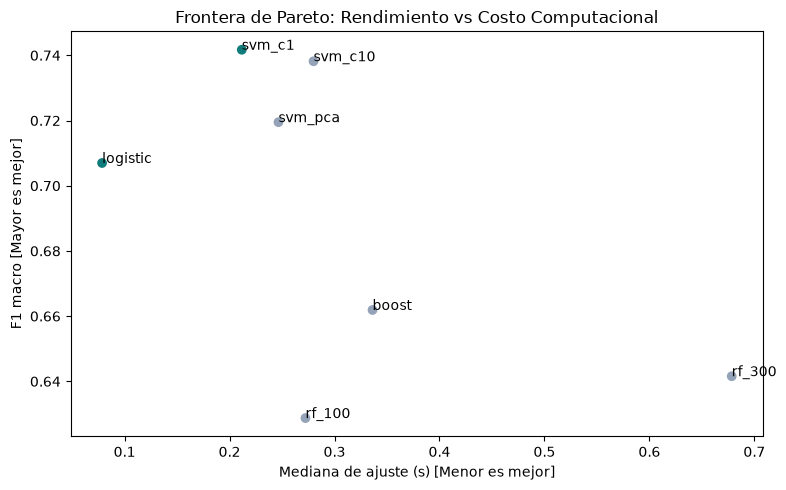

In [18]:
import matplotlib.pyplot as plt

# Generar gráfico de la Frontera de Pareto
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(results.fit_median_s, results.f1_macro, c=results.is_pareto.map({True:"#0f7c7b", False:"#94a3b8"}))

# Etiquetar cada modelo
for _, r in results.iterrows(): 
    ax.annotate(r.model, (r.fit_median_s, r.f1_macro))

ax.set(xlabel="Mediana de ajuste (s) [Menor es mejor]", ylabel="F1 macro [Mayor es mejor]", title="Frontera de Pareto: Rendimiento vs Costo Computacional")
plt.tight_layout()
plt.savefig("reports/pareto.png", dpi=160)
plt.show()

### Informe de Cuadrante y Decisión Multiobjetivo (Frontera de Pareto y Green AI)

El análisis de la Frontera de Pareto sobre el dataset *Statlog (German Credit Data)* permite evaluar cuantitativamente el equilibrio entre la calidad predictiva y la eficiencia computacional bajo los principios de Green AI. 

El rendimiento máximo en la métrica principal fue alcanzado por el modelo **`svm_c1`**, obteniendo un `f1_macro` de **0.7417** (con un *recall* macro de 0.7226). No obstante, para priorizar la eficiencia operativa y minimizar el costo computacional, la **alternativa seleccionada** en la frontera de Pareto fue el modelo de **Regresión Logística (`logistic`)**, el cual registró un `f1_macro` de **0.7070**. 

Al comparar ambas opciones, se observa una **diferencia absoluta de F1** de **0.0347** puntos en detrimento de la Regresión Logística. A cambio de esta modesta penalización en desempeño, la alternativa seleccionada ofrece un **porcentaje de ahorro temporal** masivo del **75.27%** en el tiempo de entrenamiento, reduciendo la mediana de ajuste de 0.2553 segundos a tan solo 0.0631 segundos. Asimismo, existe una **diferencia de tamaño** drástica en el artefacto serializado en disco: mientras que la SVM requiere 254.69 KB, la Regresión Logística ocupa apenas **7.49 KB**, representando una reducción neta de 247.20 KB (un ahorro superior al 96% en espacio de almacenamiento). Adicionalmente, el tiempo de inferencia unitario (`predict_ms`) mejora de forma notable de 34.37 ms a 20.31 ms.

No obstante, esta decisión conlleva **limitaciones** técnicas importantes. La Regresión Logística asume una frontera de decisión estrictamente lineal, lo que restringe su capacidad para modelar patrones y relaciones no lineales complejas entre las variables socioeconómicas y crediticias, viéndose reflejado en una leve disminución del *recall* macro (de 0.7226 a 0.6988). Esto resulta crítico si la prioridad operativa de la institución es mitigar los Falsos Negativos en la clase de riesgo de impago. 

Finalmente, cabe destacar que este análisis está condicionado por el **contexto del hardware** local de ejecución bajo un sistema operativo Windows 11 (64 bits) impulsado por un procesador Intel Core i7-10750H a 2.60 GHz, 8.00 GB de memoria RAM y una tarjeta gráfica NVIDIA GeForce GTX 1660 Ti, ejecutándose dentro de un entorno virtual aislado con paralelismo por `n_jobs`. Por tanto, los tiempos medidos mediante `perf_counter()` operan como una referencia empírica estrictamente contextual de pruebas y no como una constante universal de consumo energético absoluto.

In [19]:
import platform, sys, sklearn

print("Python:", sys.version)
print("Sistema Operativo:", platform.platform())
print("Procesador:", platform.processor())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Sistema Operativo: Windows-11-10.0.26200-SP0
Procesador: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel
scikit-learn: 1.9.1
